# White LED

## Spectral measurement

### Importing module and data

In [1]:
from spectroscopy import Spectrum
from spectroscopy import Collection
from matplotlib import pyplot as plt

In [2]:
background = Spectrum.from_txt("Background.txt")
led_spectrum = Spectrum.from_txt("LED.txt")
filtered_spectrum = Spectrum.from_txt("Filtered LED.txt")
print(background.metadata)

{'data_source': 'txt', 'Saving Time': 'Fri, Aug 14, 2026 17:38:37', 'Device Name': 'Firefly', 'Version Info': 'V1_55', 'Serial Number': '220320201226015502000850', 'Integral Time(�s)': '1000000', 'Avg Count': '1', 'Smoothness': '0', 'Data Type': '(0 0)Wavelength-Original Spectreum', 'X-Axis Unit': 'nm', 'Y-Axis Unit': 'counts', 'Pixel Count': '3403', 'Reserve0': '250', 'Other Description': ''}


### Processing

In [3]:
filtered_spectrum.subtract(background)
filtered_spectrum.smooth()

led_spectrum.subtract(background)
led_spectrum.smooth()
led_spectrum.lp_filter()
led_spectrum.find_peaks()

### Plotting

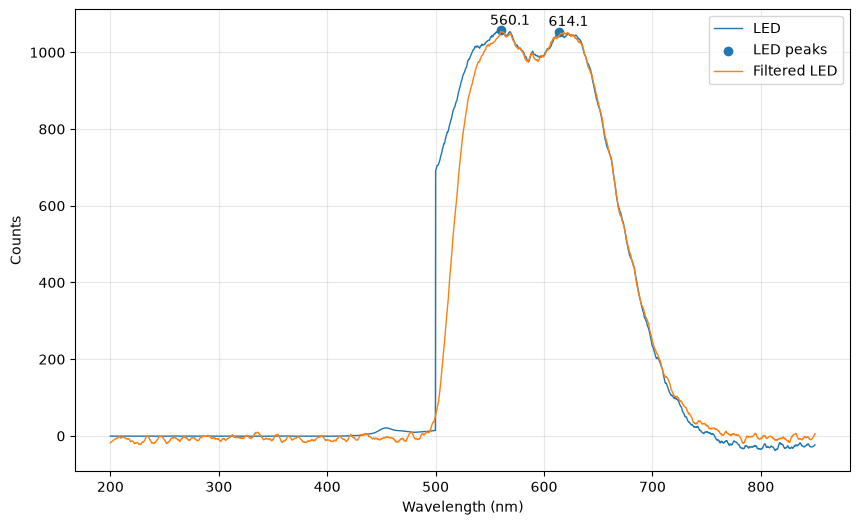

In [4]:
collection = Collection(led_spectrum, filtered_spectrum)
collection.plot()

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(led_spectrum.wavelengths, led_spectrum.counts, linewidth=1, label="Without filter")
plt.plot(filtered_spectrum.wavelengths, filtered_spectrum.counts, linewidth=1, label="With filter")
plt.scatter(led_spectrum.peaks[:, 0], led_spectrum.peaks[:, 1], label="Peaks")

ax.scatter(self.peaks[:, 0], self.peaks[:, 1], label="Peaks")
for peak in self.peaks:
    label = str(np.round(peak[0], decimals=1))# + " nm"
    offset = np.array([-10, label_y_spacing])
    ax.annotate(label, xy=peak, xytext=peak+offset)

plt.xlabel("Wavelength (nm)")
plt.ylabel("Counts")
plt.title("LED + phosphor")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()